# Challenge 1: Explainable Classification App
## Data preparation: Diabetes 130-US Hospitals (30-day readmission)

**Course:** Data Mining, ENSI, 2026-2027 · **Case:** #12 of the catalogue · **Target:** readmission within 30 days (binary)

This notebook covers **Module 1 (Data)** and **Module 2 (Preparation)** of the project sheet.

| Part | What we do |
|---|---|
| 1 | Load the data (the raw table is never modified) |
| 2 | **Inspect** the raw data: structure, target, missing values, suspicious values |
| 3 | **Clean** step by step, one decision per step, with a check after each |
| 4 | Exploratory visualisations on the cleaned data |
| 5 | Preprocessing for modelling: patient-level split + sklearn pipeline |
| 6 | Summary of decisions (useful for the oral defence) |

**Golden rule:** `df_raw` stays untouched. All cleaning happens on a copy called `df`, so any cell can be re-run safely (and *Restart & Run All* always works).

## Module 1 (Data) and Module 2 (Preparation)

## 0. Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

RANDOM_STATE = 42   # fixed seed so the split is reproducible

## 1. Load the data

The file `diabetic_data.csv` comes from the UCI repository (dataset id 296). In this file, missing values are written as the character `?`, so we tell pandas to read `?` as `NaN` right away. `low_memory=False` avoids the *mixed types* warning we saw earlier on one column.

In [2]:
# Where is the file? (Kaggle input first, then a local folder, then automatic download from UCI)
CANDIDATE_PATHS = [
    '/kaggle/input/datasets/assilbenkhadija/diabetes-130-us/diabetic_data.csv',   # Kaggle
    'data/raw/diabetic_data.csv',                                                  # local project folder
]
RAW_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
print('Using file:', RAW_PATH)

if RAW_PATH is not None:
    df_raw = pd.read_csv(RAW_PATH, na_values='?', low_memory=False)
else:
    # fallback: automatic download (this is also what the deployed app will do)
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=296)
    df_raw = pd.concat([d.data.ids, d.data.features, d.data.targets], axis=1).replace('?', np.nan)

print('Shape:', df_raw.shape)

Using file: /kaggle/input/datasets/assilbenkhadija/diabetes-130-us/diabetic_data.csv
Shape: (101766, 50)


## 2. Inspection of the raw data 

Before cleaning anything, we look at every part of the table to understand what is in it and what could go wrong. Each sub-section ends with a short **Observation** we will use to justify the cleaning decisions in Part 3.

### 2.1 First look: structure and types

In [3]:
display(df_raw.head())
print('Rows x columns:', df_raw.shape)
print()
print('Column types:')
print(df_raw.dtypes.value_counts())

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


Rows x columns: (101766, 50)

Column types:
object    37
int64     13
Name: count, dtype: int64


### 2.2 Column inventory
One summary table for all 50 columns: type, number of distinct values, number of missing values, and how dominant the most frequent value is. A column where one value covers almost all rows carries almost no information.

In [4]:
inventory = pd.DataFrame({
    'dtype':       df_raw.dtypes.astype(str),
    'n_unique':    df_raw.nunique(),
    'n_missing':   df_raw.isna().sum(),
    'pct_missing': (df_raw.isna().mean() * 100).round(1),
    'top_value':   df_raw.mode(dropna=True).iloc[0],
    'top_value_pct': (df_raw.apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0]) * 100).round(2),
})
inventory.sort_values('pct_missing', ascending=False)

,dtype,n_unique,n_missing,pct_missing,top_value,top_value_pct
weight,object,9,98569,96.9,[75-100),41.79
max_glu_serum,object,3,96420,94.7,Norm,48.58
A1Cresult,object,3,84748,83.3,>8,48.28
medical_specialty,object,72,49949,49.1,InternalMedicine,28.24
payer_code,object,17,40256,39.6,MC,52.74
race,object,5,2273,2.2,Caucasian,76.49
diag_3,object,789,1423,1.4,250,11.52
diag_2,object,748,358,0.4,276,6.66
patient_nbr,int64,71518,0,0.0,88785891.0,0.04
encounter_id,int64,101766,0,0.0,12522,0.00


**Observation.** Several columns are almost empty (`weight`), have a dominant single value (many medication columns, where "No" covers more than 99% of rows), or have a very high number of distinct values (`diag_1/2/3`, `medical_specialty`). These are the columns that need a decision in Part 3.

### 2.3 Target variable: `readmitted`
The original target has 3 values: `NO` (never readmitted), `>30` (readmitted after 30 days) and `<30` (readmitted within 30 days). The project sheet says that multi-class targets must be reduced to two classes, so our positive class will be `<30`.

In [5]:
target_counts = df_raw['readmitted'].value_counts()
target_pct = (df_raw['readmitted'].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({'count': target_counts, 'percent': target_pct}))

px.bar(x=target_counts.index, y=target_counts.values,
       labels={'x': 'readmitted', 'y': 'number of encounters'},
       title='Original target: 3 classes')

            count  percent
readmitted                
NO          54864    53.91
>30         35545    34.93
<30         11357    11.16


**Observation.** Only about 11% of encounters are readmitted within 30 days. The binary problem will therefore be **imbalanced** (roughly 1 positive for 8 negatives), so accuracy will not be a good metric. We will use AUC-ROC, PR-AUC, recall and F1 on the positive class.

### 2.4 Missing values

In [6]:
missing = df_raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({'n_missing': missing, 'pct': (missing / len(df_raw) * 100).round(1)})

,n_missing,pct
weight,98569,96.9
max_glu_serum,96420,94.7
A1Cresult,84748,83.3
medical_specialty,49949,49.1
payer_code,40256,39.6
race,2273,2.2
diag_3,1423,1.4
diag_2,358,0.4
diag_1,21,0.0


**Observation.**
- `weight` (about 97% missing), `payer_code` (about 40%) and `medical_specialty` (about 49%) are heavily incomplete.
- `max_glu_serum` and `A1Cresult` are also mostly `NaN`. Here, `NaN` does not mean "the data was lost": it means **the test was not performed** during the stay. That is information in itself, so we will keep it as a category rather than impute it.
- `race` (about 2%) and the diagnosis codes have very few missing values.

### 2.5 Identifiers and repeated patients
`encounter_id` identifies one hospital stay and `patient_nbr` identifies the patient. A patient can have several stays in the table. This matters for the train/test split.

In [7]:
print('Distinct encounter_id :', df_raw['encounter_id'].nunique(), '/', len(df_raw))
print('Distinct patients     :', df_raw['patient_nbr'].nunique())
print('Fully duplicated rows :', df_raw.duplicated().sum())

enc_per_patient = df_raw['patient_nbr'].value_counts()
print()
print('Patients with more than one encounter:',
      (enc_per_patient > 1).sum(), f'({(enc_per_patient > 1).mean()*100:.1f}% of patients)')
print('Maximum encounters for one patient   :', enc_per_patient.max())

Distinct encounter_id : 101766 / 101766
Distinct patients     : 71518
Fully duplicated rows : 0

Patients with more than one encounter: 16773 (23.5% of patients)
Maximum encounters for one patient   : 40


**Observation.** Many patients appear several times. If we split the rows randomly, the same patient could be in both train and test, and the model would be evaluated on people it has already seen (**data leakage**, which inflates the scores). We will split **by patient** (Part 5).

### 2.6 Suspicious or special values in categorical columns

In [8]:
print('--- gender ---')
print(df_raw['gender'].value_counts(dropna=False))
print()
print('--- race ---')
print(df_raw['race'].value_counts(dropna=False))
print()
print('--- age (brackets of 10 years) ---')
print(df_raw['age'].value_counts().sort_index())

--- gender ---
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

--- race ---
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

--- age (brackets of 10 years) ---
age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64


**Observation.** `gender` contains a few `Unknown/Invalid` rows (they will be removed). `age` is not a number but a **bracket** like `[70-80)`, so we will convert it to a numeric value.

### 2.7 Admission and discharge codes
`admission_type_id`, `admission_source_id` and `discharge_disposition_id` are **codes**, not quantities (code 7 is not "more" than code 3). The file `IDS_mapping.csv` explains them. We also check which discharge codes mean the patient died or went to hospice: those patients cannot be readmitted.

In [9]:
ids_path = os.path.join(os.path.dirname(RAW_PATH), 'IDS_mapping.csv') if RAW_PATH else None
if ids_path and os.path.exists(ids_path):
    print(open(ids_path).read())
else:
    print('IDS_mapping.csv not found next to the data file (not needed to run the notebook).')

admission_type_id,description
1,Emergency
2,Urgent
3,Elective
4,Newborn
5,Not Available
6,NULL
7,Trauma Center
8,Not Mapped
,
discharge_disposition_id,description
1,Discharged to home
2,Discharged/transferred to another short term hospital
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpatient care institution
6,Discharged/transferred to home with home health service
7,Left AMA
8,Discharged/transferred to home under care of Home IV provider
9,Admitted as an inpatient to this hospital
10,Neonate discharged to another hospital for neonatal aftercare
11,Expired
12,Still patient or expected to return for outpatient services
13,Hospice / home
14,Hospice / medical facility
15,Discharged/transferred within this institution to Medicare approved swing bed
16,Discharged/transferred/referred another institution for outpatient services
17,Discharged/transferred/referred to this institution for outpatient services
18,NULL
19,"Expired at

In [10]:
for col in ['admission_type_id', 'admission_source_id', 'discharge_disposition_id']:
    print(f'--- {col}: {df_raw[col].nunique()} distinct codes, top 8 ---')
    print(df_raw[col].value_counts().head(8))
    print()

--- admission_type_id: 8 distinct codes, top 8 ---
admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64

--- admission_source_id: 17 distinct codes, top 8 ---
admission_source_id
7     57494
1     29565
17     6781
4      3187
6      2264
2      1104
5       855
3       187
Name: count, dtype: int64

--- discharge_disposition_id: 26 distinct codes, top 8 ---
discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
Name: count, dtype: int64



**Observation.** In `IDS_mapping.csv`, the discharge codes **11, 13, 14, 19, 20, 21** correspond to *expired* or *hospice*. Admission and discharge columns have many rare codes, which we will group into an `Other` category.

In [11]:
dead_or_hospice = [11, 13, 14, 19, 20, 21]
n_removed = df_raw['discharge_disposition_id'].isin(dead_or_hospice).sum()
print(f'Encounters ending in death / hospice: {n_removed} ({n_removed/len(df_raw)*100:.1f}% of the table)')

Encounters ending in death / hospice: 2423 (2.4% of the table)


In [12]:
# Codes that mean "not available / NULL / not mapped" -> one 'Unknown' category
unknown_codes = {
    'admission_type_id':        ['5', '6', '8'],
    'admission_source_id':      ['9', '15', '17', '20', '21'],
    'discharge_disposition_id': ['18', '25', '26'],
}
for col, codes in unknown_codes.items():
    df_raw[col] = df_raw[col].replace(codes, 'Unknown')
    print(f'{col}: {(df_raw[col] == "Unknown").mean():.1%} of rows are Unknown')

admission_type_id: 0.0% of rows are Unknown
admission_source_id: 0.0% of rows are Unknown
discharge_disposition_id: 0.0% of rows are Unknown


### 2.8 Numeric columns

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


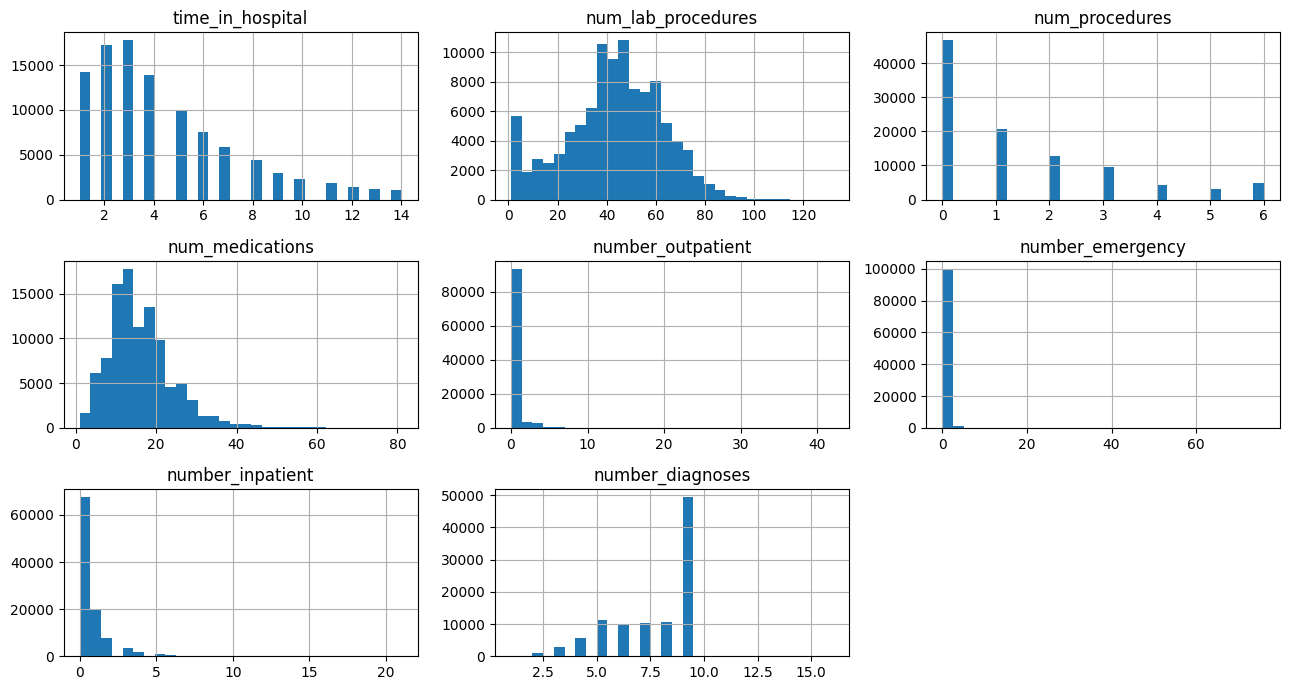

In [13]:
num_cols_raw = df_raw.select_dtypes(include='number').columns.drop(['encounter_id', 'patient_nbr',
                                      'admission_type_id', 'admission_source_id', 'discharge_disposition_id'])
display(df_raw[num_cols_raw].describe().T)

df_raw[num_cols_raw].hist(figsize=(13, 7), bins=30)
plt.tight_layout()
plt.show()

**Observation.** The prior-visit counts (`number_outpatient`, `number_emergency`, `number_inpatient`) are heavily right-skewed with a few extreme values (some patients have dozens of visits). We keep them as they are: tree models are not sensitive to outliers, and scaling will handle the rest for logistic regression and kNN. The values are real, not errors.

### 2.9 Medication columns
23 columns describe whether each diabetes drug was prescribed (`No`) or its dose was changed (`Up`, `Down`, `Steady`). We check how often each is actually used.

In [14]:
med_cols = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide',
            'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol',
            'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
            'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

med_summary = pd.DataFrame({
    'pct_No': [(df_raw[c] == 'No').mean() * 100 for c in med_cols],
    'n_levels': [df_raw[c].nunique() for c in med_cols],
}, index=med_cols).round(2).sort_values('pct_No', ascending=False)
med_summary

,pct_No,n_levels
acetohexamide,100.00,2
examide,100.00,1
glimepiride-pioglitazone,100.00,2
metformin-pioglitazone,100.00,2
citoglipton,100.00,1
metformin-rosiglitazone,100.00,2
troglitazone,100.00,2
glipizide-metformin,99.99,2
tolbutamide,99.98,2
tolazamide,99.96,3


**Observation.** Most drugs are almost never prescribed ("No" above 99%), and two of them (`examide`, `citoglipton`) have a single value for every row. A column that never varies cannot help a model, so we will drop the near-constant ones in Part 3 and keep the drugs that are actually used (`insulin`, `metformin`, `glipizide`, `glyburide`, ...).

## 3. Cleaning, step by step

From here we work on a **copy** (`df`). After every step there is a short check to confirm the step did what we wanted. The cleaning decisions come from the observations of Part 2.

### 3.0 Start from a copy of the raw data

In [15]:
df = df_raw.copy()
print('Starting shape:', df.shape)

Starting shape: (101766, 50)


### Step 1: Create the binary target
Positive class (1) = readmitted **within 30 days** (`<30`). Everything else (`>30` and `NO`) is class 0.

In [16]:
df['target'] = (df['readmitted'] == '<30').astype(int)

print(df['target'].value_counts())
print(f"Positive rate: {df['target'].mean():.4f}")

target
0    90409
1    11357
Name: count, dtype: int64
Positive rate: 0.1116


### Step 2: Remove patients who died or went to hospice
They cannot be readmitted, so keeping them would make "no readmission" look easier to predict than it really is and would bias the model.

In [17]:
before = len(df)
df = df[~df['discharge_disposition_id'].isin(dead_or_hospice)].copy()

print(f'Removed {before - len(df)} rows -> {len(df)} rows left')
print(f"Positive rate now: {df['target'].mean():.4f}")

Removed 2423 rows -> 99343 rows left
Positive rate now: 0.1139


### Step 3: Remove invalid gender rows
Only a handful of rows have `Unknown/Invalid` as gender. We have too few of them to model as their own category, so we drop them. Gender is also one of the sensitive variables we will audit later.

In [18]:
before = len(df)
df = df[df['gender'].isin(['Male', 'Female'])].copy()

print(f'Removed {before - len(df)} rows')
print(df['gender'].value_counts())

Removed 3 rows
gender
Female    53454
Male      45886
Name: count, dtype: int64


### Step 4: Drop columns that cannot help
- `encounter_id`: a pure identifier, no predictive meaning.
- `weight`: about 97% missing, impossible to impute honestly.
- `payer_code`: about 40% missing and an administrative field rather than a clinical one.
- `readmitted`: the original target. Keeping it would leak the answer into the features, so it must go (we already built `target` from it).

`patient_nbr` is **kept for now** because we need it to split by patient. It will be removed from the features in Part 5.

In [19]:
cols_to_drop = ['encounter_id', 'weight', 'payer_code', 'readmitted']
df = df.drop(columns=cols_to_drop)

print('Dropped:', cols_to_drop)
print('Shape:', df.shape)

Dropped: ['encounter_id', 'weight', 'payer_code', 'readmitted']
Shape: (99340, 47)


### Step 5: Handle missing values
Different columns need different treatments:

| Column | Meaning of `NaN` | Treatment |
|---|---|---|
| `A1Cresult`, `max_glu_serum` | test **not performed** | new category `Not measured` (informative, not a gap) |
| `race` | not recorded | category `Unknown` (only about 2%) |
| `medical_specialty` | not recorded | category `Unknown` (about 49%, too many to drop rows) |

In [20]:
df['A1Cresult'] = df['A1Cresult'].fillna('Not measured')
df['max_glu_serum'] = df['max_glu_serum'].fillna('Not measured')
df['race'] = df['race'].fillna('Unknown')
df['medical_specialty'] = df['medical_specialty'].fillna('Unknown')

print(df[['A1Cresult', 'max_glu_serum', 'race', 'medical_specialty']].isna().sum())
print()
print(df['A1Cresult'].value_counts())

A1Cresult            0
max_glu_serum        0
race                 0
medical_specialty    0
dtype: int64

A1Cresult
Not measured    82506
>8               8137
Norm             4922
>7               3775
Name: count, dtype: int64


### Step 6: Group the primary diagnosis (ICD-9) into families
`diag_1` contains hundreds of distinct ICD-9 codes. As raw categories they would create hundreds of columns after one-hot encoding, most with very few patients. We group the codes into the main clinical families (circulatory, respiratory, diabetes, ...).

We keep only the **primary** diagnosis `diag_1` to stay simple and easy to explain. `diag_2` and `diag_3` (secondary diagnoses) are dropped.

In [21]:
def icd_group(code):
    """Map an ICD-9 code (string) to a broad clinical family."""
    if pd.isna(code):
        return 'Unknown'
    s = str(code)
    if s.startswith(('V', 'E')):          # supplementary codes
        return 'Other'
    if s.startswith('250'):               # 250.xx = diabetes mellitus
        return 'Diabetes'
    try:
        c = float(s)
    except ValueError:
        return 'Other'
    if 390 <= c <= 459 or c == 785: return 'Circulatory'
    if 460 <= c <= 519 or c == 786: return 'Respiratory'
    if 520 <= c <= 579 or c == 787: return 'Digestive'
    if 580 <= c <= 629 or c == 788: return 'Genitourinary'
    if 710 <= c <= 739:             return 'Musculoskeletal'
    if 800 <= c <= 999:             return 'Injury'
    if 140 <= c <= 239:             return 'Neoplasms'
    return 'Other'

df['diag_1_grp'] = df['diag_1'].apply(icd_group)
df = df.drop(columns=['diag_1', 'diag_2', 'diag_3'])

print(df['diag_1_grp'].value_counts())

diag_1_grp
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Unknown               20
Name: count, dtype: int64


### Step 7: Convert `age` brackets to numbers
`[70-80)` becomes `75`, the middle of the interval. This keeps the natural order of ages, which a model can use, and gives one numeric column instead of 10 dummy columns.

In [22]:
df['age'] = df['age'].str.extract(r'\[(\d+)-')[0].astype(int) + 5

print(df['age'].value_counts().sort_index())

age
5       160
15      690
25     1649
35     3764
45     9607
55    17060
65    22058
75    25329
85    16434
95     2589
Name: count, dtype: int64


### Step 8: Treat ID codes as categories and group the rare ones
`admission_type_id`, `admission_source_id` and `discharge_disposition_id` are labels, not quantities, so they are converted to text and will be one-hot encoded later.

Many of their codes (and many `medical_specialty` values) are very rare. A category with a handful of patients cannot be learned reliably, so every category below **1%** of the rows is merged into `Other`. This rule only uses frequencies, never the target.

In [23]:
def group_rare(series, min_freq=0.01, other_label='Other'):
    """Keep categories that cover at least `min_freq` of the rows; merge the others into `other_label`."""
    freq = series.value_counts(normalize=True)
    keep = freq[freq >= min_freq].index
    return series.where(series.isin(keep), other_label)

for col in ['admission_type_id', 'admission_source_id', 'discharge_disposition_id']:
    df[col] = df[col].astype(str)

for col in ['admission_type_id', 'admission_source_id', 'discharge_disposition_id', 'medical_specialty']:
    n_before = df[col].nunique()
    df[col] = group_rare(df[col], min_freq=0.01)
    print(f'{col:28s}: {n_before:3d} categories -> {df[col].nunique():3d}')

admission_type_id           :   8 categories ->   6
admission_source_id         :  17 categories ->   7
discharge_disposition_id    :  21 categories ->   8
medical_specialty           :  73 categories ->  11


### Step 9: Drop near-constant medication columns
A column where one value covers more than **99.5%** of the rows has almost no variation, so a model cannot learn from it. We detect them automatically among the categorical columns and look at the list before dropping.

In [24]:
cat_cols_now = df.select_dtypes(exclude='number').columns

dominance = pd.Series({c: df[c].value_counts(normalize=True).iloc[0] for c in cat_cols_now})
near_constant = dominance[dominance > 0.995].sort_values(ascending=False)

print('Columns dominated by a single value (> 99.5%):')
print((near_constant * 100).round(2))

Columns dominated by a single value (> 99.5%):
citoglipton                 100.00
examide                     100.00
metformin-pioglitazone      100.00
glimepiride-pioglitazone    100.00
acetohexamide               100.00
metformin-rosiglitazone     100.00
troglitazone                100.00
glipizide-metformin          99.99
tolbutamide                  99.98
miglitol                     99.96
tolazamide                   99.96
chlorpropamide               99.91
acarbose                     99.69
dtype: float64


In [25]:
df = df.drop(columns=near_constant.index)

print('Dropped', len(near_constant), 'columns. New shape:', df.shape)

Dropped 13 columns. New shape: (99340, 32)


### Step 10: Final checks on the cleaned table

In [26]:
# 1. no missing values left
assert df.isna().sum().sum() == 0, 'There are still missing values'
# 2. target is binary
assert set(df['target'].unique()) <= {0, 1}
# 3. no excluded discharge codes remain (they are strings now)
assert not df['discharge_disposition_id'].isin([str(c) for c in dead_or_hospice]).any()

print('Shape            :', df.shape)
print(f"Positive rate    : {df['target'].mean():.4f}")
print('Missing values   :', df.isna().sum().sum())
print()
print(df.dtypes.value_counts())
df.head()

Shape            : (99340, 32)
Positive rate    : 0.1139
Missing values   : 0

object    21
int64     11
Name: count, dtype: int64


,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin,glyburide-metformin,change,diabetesMed,target,diag_1_grp
0,8222157,Caucasian,Female,5,6,Other,1,1,Other,41,0,1,0,0,0,1,Not measured,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,0,Diabetes
1,55629189,Caucasian,Female,15,1,1,7,3,Unknown,59,0,18,0,0,0,9,Not measured,Not measured,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,0,Other
2,86047875,AfricanAmerican,Female,25,1,1,7,2,Unknown,11,5,13,2,0,1,6,Not measured,Not measured,No,No,No,No,Steady,No,No,No,No,No,No,Yes,0,Other
3,82442376,Caucasian,Male,35,1,1,7,2,Unknown,44,1,16,0,0,0,7,Not measured,Not measured,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,0,Other
4,42519267,Caucasian,Male,45,1,1,7,1,Unknown,51,0,8,0,0,0,5,Not measured,Not measured,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,0,Neoplasms


## 4. Exploratory visualisations (Module 1)

The project sheet asks for interactive plots: distributions, correlations and the **rate of the positive class per variable**. We use a small helper that draws the 30-day readmission rate for each value of a variable, with the dashed line showing the overall rate for comparison.

In [27]:
overall_rate = df['target'].mean()

def rate_by(col, data=None, title=None):
    """Bar chart of the positive-class rate for each value of `col`."""
    data = df if data is None else data
    g = (data.groupby(col)['target'].agg(rate='mean', n='size').reset_index())
    fig = px.bar(g, x=col, y='rate', hover_data=['n'],
                 title=title or f'30-day readmission rate by {col}')
    fig.add_hline(y=overall_rate, line_dash='dash', annotation_text=f'overall {overall_rate:.1%}')
    fig.update_layout(yaxis_tickformat='.0%')
    fig.show()

### 4.1 Class balance after cleaning

In [28]:
bal = df['target'].value_counts().rename({0: 'not readmitted <30d', 1: 'readmitted <30d'})
px.pie(values=bal.values, names=bal.index, title='Class balance (binary target)')

### 4.2 Readmission rate by age

In [29]:
rate_by('age')

### 4.3 Readmission rate by number of previous inpatient visits
We cap the count at 5 so the rare extreme values do not stretch the chart (this is for display only, the data is unchanged).

In [30]:
tmp = df.assign(number_inpatient_capped=df['number_inpatient'].clip(upper=5))
rate_by('number_inpatient_capped', data=tmp, title='30-day readmission rate by prior inpatient visits (5 = 5 or more)')

### 4.4 Readmission rate by primary diagnosis family

In [31]:
rate_by('diag_1_grp')

### 4.5 Readmission rate by HbA1c result

In [32]:
rate_by('A1Cresult')

### 4.6 Readmission rate by discharge destination

In [33]:
rate_by('discharge_disposition_id')

### 4.7 Sensitive variables: race and gender
We look at them now because they matter for the fairness analysis requested in the one-pager.

In [34]:
rate_by('race')
rate_by('gender')

### 4.8 Correlations between numeric variables

In [35]:
num_for_corr = df.select_dtypes(include='number').drop(columns=['patient_nbr'])
corr = num_for_corr.corr().round(2)

px.imshow(corr, text_auto=True, color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
          title='Correlation matrix (numeric variables)', aspect='auto')

**Observation.** Correlations with the target are weak for every single variable, which is typical of readmission data and explains why a modest AUC is expected. `num_medications` and `time_in_hospital` are moderately correlated with each other, which is clinically logical (longer stays mean more drugs).

## 5. Preprocessing for modelling (Module 2)

### 5.1 Define features and target
- **Target:** `target`
- **Group identifier (not a feature):** `patient_nbr`, used only to split by patient.
- **Sensitive variables:** `race`, `gender`, `age`. We keep them in the data for now so we can (a) measure fairness and (b) compare the models with and without them.

In [36]:
TARGET = 'target'
GROUP = 'patient_nbr'
SENSITIVE = ['race', 'gender', 'age']

feature_cols = [c for c in df.columns if c not in (TARGET, GROUP)]
num_cols = df[feature_cols].select_dtypes(include='number').columns.tolist()
cat_cols = df[feature_cols].select_dtypes(exclude='number').columns.tolist()

print(f'{len(feature_cols)} features = {len(num_cols)} numeric + {len(cat_cols)} categorical')
print()
print('Numeric    :', num_cols)
print()
print('Categorical:', cat_cols)

30 features = 9 numeric + 21 categorical

Numeric    : ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical: ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed', 'diag_1_grp']


### 5.2 Train / test split **by patient**
We use `GroupShuffleSplit` with `patient_nbr` as the group: every patient goes entirely to train **or** to test, never both. This prevents the leakage described in section 2.5. The test size is a parameter (the app will expose it in a slider).

In [37]:
from sklearn.model_selection import GroupShuffleSplit

def split_by_patient(data, test_size=0.2, seed=RANDOM_STATE):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(gss.split(data, groups=data[GROUP]))
    return data.iloc[train_idx].copy(), data.iloc[test_idx].copy()

train, test = split_by_patient(df, test_size=0.2)

# checks
overlap = set(train[GROUP]) & set(test[GROUP])
print('Patients in both train and test:', len(overlap), '(must be 0)')
print(f"Train: {len(train):6d} rows, positive rate {train[TARGET].mean():.4f}")
print(f"Test : {len(test):6d} rows, positive rate {test[TARGET].mean():.4f}")
assert len(overlap) == 0

Patients in both train and test: 0 (must be 0)
Train:  79567 rows, positive rate 0.1140
Test :  19773 rows, positive rate 0.1135


### 5.3 Preprocessing pipeline
Built with scikit-learn's `ColumnTransformer` so the **same transformation** is applied identically in training, in the app and in the API:

- **Numeric:** median imputation (safety net, there are no missing values now) then standardisation. Scaling matters for logistic regression and kNN.
- **Categorical:** most-frequent imputation (safety net) then one-hot encoding. `handle_unknown='ignore'` avoids a crash if a category appears only in the test set.

The pipeline is **fitted on the training set only** and then applied to the test set. Fitting on the full data would let information from the test set leak into the preprocessing.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(num_cols, cat_cols):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    pre = ColumnTransformer([('num', numeric, num_cols),
                             ('cat', categorical, cat_cols)])
    pre.set_output(transform='pandas')      # keep column names (needed later for SHAP / LIME)
    return pre

X_train, y_train = train[feature_cols], train[TARGET]
X_test,  y_test  = test[feature_cols],  test[TARGET]

preprocessor = build_preprocessor(num_cols, cat_cols)
X_train_t = preprocessor.fit_transform(X_train)     # fit on TRAIN only
X_test_t  = preprocessor.transform(X_test)          # only transform on TEST

print('Train matrix:', X_train_t.shape)
print('Test matrix :', X_test_t.shape)
print('Same columns in train and test:', list(X_train_t.columns) == list(X_test_t.columns))
X_train_t.head()

Train matrix: (79567, 111)
Test matrix : (19773, 111)
Same columns in train and test: True


,num__age,num__time_in_hospital,num__num_lab_procedures,num__num_procedures,num__num_medications,num__number_outpatient,num__number_emergency,num__number_inpatient,num__number_diagnoses,cat__race_AfricanAmerican,cat__race_Asian,cat__race_Caucasian,cat__race_Hispanic,cat__race_Other,cat__race_Unknown,cat__gender_Female,cat__gender_Male,cat__admission_type_id_1,cat__admission_type_id_2,cat__admission_type_id_3,cat__admission_type_id_5,cat__admission_type_id_6,cat__admission_type_id_Other,cat__discharge_disposition_id_1,cat__discharge_disposition_id_18,cat__discharge_disposition_id_2,cat__discharge_disposition_id_22,cat__discharge_disposition_id_3,cat__discharge_disposition_id_5,cat__discharge_disposition_id_6,...,cat__pioglitazone_Down,cat__pioglitazone_No,cat__pioglitazone_Steady,cat__pioglitazone_Up,cat__rosiglitazone_Down,cat__rosiglitazone_No,cat__rosiglitazone_Steady,cat__rosiglitazone_Up,cat__insulin_Down,cat__insulin_No,cat__insulin_Steady,cat__insulin_Up,cat__glyburide-metformin_Down,cat__glyburide-metformin_No,cat__glyburide-metformin_Steady,cat__glyburide-metformin_Up,cat__change_Ch,cat__change_No,cat__diabetesMed_No,cat__diabetesMed_Yes,cat__diag_1_grp_Circulatory,cat__diag_1_grp_Diabetes,cat__diag_1_grp_Digestive,cat__diag_1_grp_Genitourinary,cat__diag_1_grp_Injury,cat__diag_1_grp_Musculoskeletal,cat__diag_1_grp_Neoplasms,cat__diag_1_grp_Other,cat__diag_1_grp_Respiratory,cat__diag_1_grp_Unknown
0,-3.818884,-1.140772,-0.099062,-0.781829,-1.847208,-0.292754,-0.205158,-0.503576,-3.296768,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-3.190479,-0.466768,0.820753,-0.781829,0.246594,-0.292754,-0.205158,-0.503576,0.822758,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-2.562074,-0.803770,-1.632086,2.157798,-0.369230,1.311432,-0.205158,0.289819,-0.722064,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-1.933669,-0.803770,0.054241,-0.193904,0.000265,-0.292754,-0.205158,-0.503576,-0.207123,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.305264,-1.140772,0.411946,-0.781829,-0.985054,-0.292754,-0.205158,-0.503576,-1.237005,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


### 5.4 Save the results
We save the cleaned train/test tables (with `patient_nbr` and `target`) and the fitted pipeline, so the modelling notebook and the app can reuse them without repeating the cleaning.

In [39]:
import joblib

OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

train.to_csv(f'{OUT_DIR}/train.csv', index=False)
test.to_csv(f'{OUT_DIR}/test.csv', index=False)
joblib.dump(preprocessor, f'{OUT_DIR}/preprocessor.joblib')

print('Saved in', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

Saved in /kaggle/working : ['__notebook__.ipynb', 'preprocessor.joblib', 'test.csv', 'train.csv']


## 6. Summary of decisions

| # | Decision | Reason |
|---|---|---|
| 1 | Binary target: `<30` = 1, everything else = 0 | The project sheet requires a binary target; about 11% positives, so the problem is imbalanced |
| 2 | Removed death / hospice discharges | These patients cannot be readmitted, which would bias the target |
| 3 | Removed invalid gender rows | Only a handful of rows, too few to model |
| 4 | Dropped `encounter_id`, `weight`, `payer_code`, `readmitted` | Identifier, about 97% missing, administrative, and the original target (leakage) |
| 5 | `NaN` in `A1Cresult` / `max_glu_serum` -> "Not measured" | Missing means the test was not done, which is informative |
| 6 | `diag_1` grouped into clinical families; `diag_2/3` dropped | Hundreds of ICD-9 codes would explode the number of columns |
| 7 | `age` bracket -> midpoint | Keeps the natural order, one column instead of ten |
| 8 | ID codes as categories; categories below 1% grouped as `Other` | Codes are labels, not quantities; rare categories cannot be learned |
| 9 | Dropped near-constant medication columns | A column that never varies carries no information |
| 10 | Split **by patient** (`GroupShuffleSplit`) | The same patient has several encounters; a random split would leak |
| 11 | Pipeline fitted on train only | Prevents test information leaking into the preprocessing |
| 12 | Kept `race`, `gender`, `age` as features | Needed for the fairness audit; models will be compared with and without them |

### Limits to mention
- We kept **all encounters** of each patient (the original study kept only the first). We handle the dependence between encounters by splitting by patient, but the encounters of one patient remain correlated inside the training set.
- The data covers US hospitals from 1999 to 2008, so the conclusions may not transfer to other countries or periods.
- Only the primary diagnosis is used; the secondary diagnoses could add signal.

### Next steps
Models (logistic regression, decision tree, kNN, Random Forest, XGBoost) with hyperparameter tuning, then evaluation (ROC, PR, threshold slider), then SHAP / LIME.

## Module 3 and Module 4

In [40]:
import os, json, time, glob, shutil, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import joblib, sklearn, xgboost

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__, '| pandas', pd.__version__)

scikit-learn 1.6.1 | xgboost 3.4.1 | pandas 2.3.3


## 1. Load the data from Modules 1 and 2

We look for `train.csv` / `test.csv` in the Kaggle working folder first, then in a local folder.

**Important detail:** `admission_type_id`, `admission_source_id` and `discharge_disposition_id` are *codes* (categories). When a CSV is re-read, pandas may turn them back into numbers, so we force them to text.

In [41]:
CANDIDATE_DIRS = ['/kaggle/working', 'outputs', '.'] + [os.path.dirname(p) for p in glob.glob('/kaggle/working/train.csv')]
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f'{d}/train.csv') and os.path.exists(f'{d}/test.csv')), None)
assert DATA_DIR is not None, 'train.csv / test.csv not found: run the preprocessing notebook first (or add its output as input)'
print('Reading from:', DATA_DIR)

ID_CODE_COLS = ['admission_type_id', 'admission_source_id', 'discharge_disposition_id']
dtypes = {c: str for c in ID_CODE_COLS}

train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=dtypes)
test  = pd.read_csv(f'{DATA_DIR}/test.csv',  dtype=dtypes)
print('train:', train.shape, '| test:', test.shape)

Reading from: /kaggle/working
train: (79567, 32) | test: (19773, 32)


In [42]:
TARGET = 'target'
GROUP = 'patient_nbr'          # only used to group patients in cross-validation, never a feature

feature_cols = [c for c in train.columns if c not in (TARGET, GROUP)]
num_cols = train[feature_cols].select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in feature_cols if c not in num_cols]

X_train, y_train, g_train = train[feature_cols], train[TARGET], train[GROUP]
X_test,  y_test           = test[feature_cols],  test[TARGET]

print(f'{len(feature_cols)} features = {len(num_cols)} numeric + {len(cat_cols)} categorical')
print(f'Positive rate: train {y_train.mean():.4f} | test {y_test.mean():.4f}')
print('Patients shared between train and test:', len(set(train[GROUP]) & set(test[GROUP])), '(must be 0)')
assert not set(train[GROUP]) & set(test[GROUP])

30 features = 9 numeric + 21 categorical
Positive rate: train 0.1140 | test 0.1135
Patients shared between train and test: 0 (must be 0)


### 1.1 The preprocessing pipeline
Same recipe as Module 2: median imputation + standardisation for numeric columns, most-frequent imputation + one-hot encoding for categorical columns. We rebuild it here (instead of loading the saved file) so this notebook works even if the library versions differ. It is placed **inside** each model pipeline, so during cross-validation it is re-fitted on each training fold only (no leakage).

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(num_cols, cat_cols):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    pre = ColumnTransformer([('num', numeric, num_cols), ('cat', categorical, cat_cols)])
    pre.set_output(transform='pandas')       # keeps feature names (needed for SHAP / LIME later)
    return pre

preprocessor = build_preprocessor(num_cols, cat_cols)
Xt = preprocessor.fit_transform(X_train)
print('Transformed training matrix:', Xt.shape)

# XGBoost refuses feature names containing [ ] or <  -> check now rather than fail later
bad = [c for c in Xt.columns if any(ch in c for ch in '[]<')]
print('Feature names XGBoost cannot accept:', bad)
assert not bad

Transformed training matrix: (79567, 111)
Feature names XGBoost cannot accept: []


## 2. Module 3: choice of models and hyperparameters

The project sheet asks for five models: **logistic regression, decision tree, k nearest neighbours, Random Forest and XGBoost**, with hyperparameter optimisation. The next cell is also what the app's interface will expose (which models, which settings).

**Handling the imbalance, without resampling.** We use *class weights*: errors on the rare positive class cost more during training (`class_weight='balanced'` for logistic regression, tree and forest; `scale_pos_weight` for XGBoost). kNN has no such option, so it stays unweighted. Set `USE_CLASS_WEIGHT = False` to see the difference (a good extra experiment for the one-pager).

In [44]:
from scipy.stats import loguniform, randint, uniform
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

USE_CLASS_WEIGHT = True
cw = 'balanced' if USE_CLASS_WEIGHT else None
scale_pos = (y_train == 0).sum() / (y_train == 1).sum() if USE_CLASS_WEIGHT else 1.0
print(f'class_weight = {cw} | XGBoost scale_pos_weight = {scale_pos:.2f}')

# name -> (estimator, search space, number of random-search trials)
MODEL_SPACE = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, class_weight=cw),
        {'clf__C': loguniform(1e-3, 1e2)}, 8),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE),
        {'clf__max_depth': randint(3, 12), 'clf__min_samples_leaf': randint(20, 200)}, 10),
    'kNN': (
        KNeighborsClassifier(n_jobs=-1),
        {'clf__n_neighbors': randint(15, 100), 'clf__weights': ['uniform', 'distance']}, 5),
    'Random Forest': (
        RandomForestClassifier(n_estimators=200, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE),
        {'clf__max_depth': randint(5, 20), 'clf__min_samples_leaf': randint(5, 50),
         'clf__max_features': ['sqrt', 0.3]}, 8),
    'XGBoost': (
        XGBClassifier(n_estimators=300, tree_method='hist', eval_metric='logloss',
                      scale_pos_weight=scale_pos, n_jobs=-1, random_state=RANDOM_STATE),
        {'clf__max_depth': randint(2, 7), 'clf__learning_rate': uniform(0.02, 0.18),
         'clf__subsample': uniform(0.6, 0.4), 'clf__colsample_bytree': uniform(0.5, 0.5),
         'clf__min_child_weight': randint(1, 20)}, 15),
}

MODELS_TO_TRAIN = list(MODEL_SPACE)      # remove names from this list to train fewer models
print('Models:', MODELS_TO_TRAIN)

class_weight = balanced | XGBoost scale_pos_weight = 7.77
Models: ['Logistic Regression', 'Decision Tree', 'kNN', 'Random Forest', 'XGBoost']


## 3. Hyperparameter tuning

How the search works, in plain words:
- **Random search** tries a limited number of random combinations from the ranges above. It is much cheaper than a full grid and usually finds almost as good settings.
- **Scoring = PR-AUC** (`average_precision`), the right metric for a rare positive class.
- **`GroupKFold` on `patient_nbr`**: in each cross-validation fold, a patient is entirely in the training part or in the validation part, never both. This is the same leakage protection as the train/test split.
- **Time saving:** (kNN is the slowest at prediction time because it compares each test row with all training rows.) The search runs on a random sample of the training set (`TUNE_SAMPLE` rows). The best settings are then used to **fit the final model on the full training set**.

In [45]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

TUNE_SAMPLE = 25000          # rows used for the search (lower it if Kaggle is slow)
CV_FOLDS = 3

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_train), size=min(TUNE_SAMPLE, len(X_train)), replace=False)
X_tune, y_tune, g_tune = X_train.iloc[idx], y_train.iloc[idx], g_train.iloc[idx]
print('Rows used for tuning:', len(X_tune), '| positives:', int(y_tune.sum()))

def make_pipeline(estimator):
    return Pipeline([('pre', clone(preprocessor)), ('clf', clone(estimator))])

best_params, cv_scores, fit_times = {}, {}, {}

for name in MODELS_TO_TRAIN:
    est, space, n_iter = MODEL_SPACE[name]
    t0 = time.time()
    search = RandomizedSearchCV(make_pipeline(est), space, n_iter=n_iter,
                                scoring='average_precision',
                                cv=GroupKFold(n_splits=CV_FOLDS),
                                random_state=RANDOM_STATE, n_jobs=1, refit=False)
    search.fit(X_tune, y_tune, groups=g_tune)
    best_params[name] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()}   # plain Python numbers
    cv_scores[name] = search.best_score_
    print(f'{name:20s} best CV PR-AUC = {search.best_score_:.4f}  ({time.time()-t0:5.0f}s)  {best_params[name]}')

Rows used for tuning: 25000 | positives: 2894
Logistic Regression  best CV PR-AUC = 0.2052  (   33s)  {'clf__C': 0.0060252157362038605}
Decision Tree        best CV PR-AUC = 0.1997  (   10s)  {'clf__max_depth': 9, 'clf__min_samples_leaf': 199}
kNN                  best CV PR-AUC = 0.1916  (   16s)  {'clf__n_neighbors': 97, 'clf__weights': 'uniform'}
Random Forest        best CV PR-AUC = 0.2154  (   43s)  {'clf__max_depth': 9, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 28}
XGBoost              best CV PR-AUC = 0.2134  (   42s)  {'clf__colsample_bytree': 0.7962072844310213, 'clf__learning_rate': 0.02836107428959959, 'clf__max_depth': 4, 'clf__min_child_weight': 7, 'clf__subsample': 0.6682096494749166}


**How to read this.** The CV PR-AUC is computed on validation folds inside the training data. The baseline of a random classifier is the positive rate (about 0.11), so any value clearly above it means the model finds real signal. Do not expect high numbers on readmission data.

## 4. Final models and comparison table

Each model is re-fitted with its best settings on the **whole training set**, then scored on the **test set**, which it has never seen (and which contains different patients).

In [46]:
fitted, proba_test, fit_times = {}, {}, {}

for name in MODELS_TO_TRAIN:
    est = MODEL_SPACE[name][0]
    pipe = make_pipeline(est).set_params(**best_params[name])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_times[name] = time.time() - t0
    fitted[name] = pipe
    proba_test[name] = pipe.predict_proba(X_test)[:, 1]
    print(f'{name:20s} fitted in {fit_times[name]:5.1f}s')

Logistic Regression  fitted in   1.8s
Decision Tree        fitted in   1.5s
kNN                  fitted in   0.8s
Random Forest        fitted in  11.5s
XGBoost              fitted in   3.0s


## 5. Module 4: evaluation metrics

For the **positive class (readmitted within 30 days)**:
- **AUC-ROC**: probability that a random positive gets a higher score than a random negative (ranking quality, 0.5 = random).
- **PR-AUC**: area under the precision-recall curve. Its baseline is the positive rate, so we also show the **lift** (PR-AUC divided by the positive rate).
- **Precision**: among patients flagged, the share really readmitted.
- **Recall**: among patients really readmitted, the share we flagged.
- **F1**: harmonic mean of precision and recall.

Precision, recall and F1 depend on the **decision threshold**. We show them at the default 0.5 here and explore other thresholds in part 7.

In [47]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, roc_curve, precision_recall_curve,
                             confusion_matrix, brier_score_loss)

prevalence = y_test.mean()

def evaluate(y_true, p, thr=0.5):
    """All metrics for one model at one threshold."""
    pred = (p >= thr).astype(int)
    pr_auc = average_precision_score(y_true, p)
    return {'AUC-ROC': roc_auc_score(y_true, p),
            'PR-AUC': pr_auc,
            'PR-AUC lift': pr_auc / prevalence,
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'Flagged %': pred.mean() * 100}

THRESHOLD = 0.5
results = pd.DataFrame({n: evaluate(y_test, p, THRESHOLD) for n, p in proba_test.items()}).T
results['CV PR-AUC (tuning)'] = pd.Series(cv_scores)
results['Fit time (s)'] = pd.Series(fit_times)
results = results.sort_values('PR-AUC', ascending=False)

print(f'Test positive rate (PR-AUC baseline): {prevalence:.4f} | threshold = {THRESHOLD}')
results.round(3)

Test positive rate (PR-AUC baseline): 0.1135 | threshold = 0.5


,AUC-ROC,PR-AUC,PR-AUC lift,Precision,Recall,F1,Flagged %,CV PR-AUC (tuning),Fit time (s)
XGBoost,0.676,0.234,2.062,0.179,0.587,0.275,37.136,0.213,3.048
Random Forest,0.674,0.232,2.042,0.183,0.577,0.278,35.725,0.215,11.542
Logistic Regression,0.668,0.219,1.928,0.183,0.547,0.275,33.859,0.205,1.775
Decision Tree,0.649,0.211,1.855,0.168,0.602,0.262,40.737,0.200,1.474
kNN,0.635,0.205,1.811,0.765,0.006,0.011,0.086,0.192,0.845


**How to read the table.**
- Rank the models mainly by **PR-AUC** and **AUC-ROC** (they do not depend on a threshold).
- Compare the CV PR-AUC with the test PR-AUC: a large gap would mean overfitting to the tuning data.
- A model with high recall and low precision flags many patients (see the *Flagged %* column). Which balance is right is a business decision, handled in part 7.
- **kNN may show precision = recall = 0 at threshold 0.5.** kNN has no class weights, so its probabilities rarely reach 0.5 for a rare class. This is not a bug: judge it with AUC / PR-AUC, or lower its threshold in part 7. It is a good point to mention to your professor.
- It is normal if XGBoost and logistic regression are close. That is the interpretability vs performance trade-off asked in the one-pager.

## 6. ROC curves, precision-recall curves and confusion matrix

### 6.1 ROC curves of all models

In [48]:
fig = go.Figure()
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines',
                             name=f'{name} (AUC {roc_auc_score(y_test, p):.3f})'))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(dash='dash', color='grey'), name='random'))
fig.update_layout(title='ROC curves (test set)', xaxis_title='False positive rate',
                  yaxis_title='True positive rate (recall)', height=520)
fig.show()

### 6.2 Precision-recall curves
With a rare positive class this curve is more informative than the ROC curve. The dashed line is the baseline (a random model has a precision equal to the positive rate).

In [49]:
fig = go.Figure()
for name, p in proba_test.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    fig.add_trace(go.Scatter(x=rec, y=prec, mode='lines',
                             name=f'{name} (PR-AUC {average_precision_score(y_test, p):.3f})'))
fig.add_hline(y=prevalence, line_dash='dash', line_color='grey', annotation_text=f'baseline {prevalence:.3f}')
fig.update_layout(title='Precision-recall curves (test set)', xaxis_title='Recall',
                  yaxis_title='Precision', height=520)
fig.show()

### 6.3 Confusion matrix
Pick the model to inspect (by default the best PR-AUC). Rows are the truth, columns are the prediction. Reading it: top-right = false alarms (flagged but not readmitted), bottom-left = **missed readmissions** (the costly errors).

In [50]:
BEST_MODEL = results.index[0]          # best PR-AUC; you can type a model name instead
print('Selected model:', BEST_MODEL)

def plot_confusion(name, thr):
    pred = (proba_test[name] >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    fig = px.imshow(cm, text_auto=True, color_continuous_scale='Blues',
                    x=['predicted: no', 'predicted: yes'], y=['actual: no', 'actual: yes'],
                    title=f'Confusion matrix: {name} (threshold {thr:.2f})')
    fig.update_layout(height=450, coloraxis_showscale=False)
    fig.show()
    tn, fp, fn, tp = cm.ravel()
    print(f'TP={tp}  FN={fn} (missed)  FP={fp} (false alarms)  TN={tn}')

plot_confusion(BEST_MODEL, THRESHOLD)

Selected model: XGBoost


TP=1318  FN=926 (missed)  FP=6025 (false alarms)  TN=11504


## 7. Decision threshold

A model outputs a **probability**. The threshold turns it into a decision ("flag this patient for follow-up"). Lowering the threshold catches more true readmissions (higher recall) but flags more patients (lower precision). The app will have a slider for this; here is the same analysis in code.

### 7.1 Precision, recall and F1 as the threshold moves

In [51]:
def threshold_table(y_true, p, thresholds=None):
    thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2) if thresholds is None else thresholds
    rows = []
    for t in thresholds:
        pred = (p >= t).astype(int)
        rows.append({'threshold': t,
                     'precision': precision_score(y_true, pred, zero_division=0),
                     'recall': recall_score(y_true, pred),
                     'f1': f1_score(y_true, pred, zero_division=0),
                     'flagged_%': pred.mean() * 100,
                     'FN': int(((pred == 0) & (y_true == 1)).sum()),
                     'FP': int(((pred == 1) & (y_true == 0)).sum())})
    return pd.DataFrame(rows)

tt = threshold_table(y_test, proba_test[BEST_MODEL])

fig = go.Figure()
for col in ['precision', 'recall', 'f1']:
    fig.add_trace(go.Scatter(x=tt['threshold'], y=tt[col], mode='lines+markers', name=col))
fig.update_layout(title=f'Effect of the threshold: {BEST_MODEL}', xaxis_title='decision threshold',
                  yaxis_title='value', height=480)
fig.show()
tt.round(3)

,threshold,precision,recall,f1,flagged_%,FN,FP
0,0.05,0.113,1.000,0.204,100.000,0,17529
1,0.10,0.113,1.000,0.204,99.995,0,17528
2,0.15,0.114,1.000,0.204,99.818,1,17494
3,0.20,0.114,0.999,0.205,99.226,2,17378
4,0.25,0.117,0.992,0.209,96.526,18,16860
5,0.30,0.122,0.963,0.217,89.288,82,15493
6,0.35,0.133,0.906,0.231,77.570,210,13304
7,0.40,0.145,0.820,0.247,63.996,405,10815
8,0.45,0.162,0.713,0.263,50.033,645,8294
9,0.50,0.179,0.587,0.275,37.136,926,6025


**Observation to write in the one-pager.** Show how recall and the share of flagged patients change between a low and a high threshold, and say which one a hospital could afford (a follow-up call is cheap, a missed readmission is not).

### 7.2 Choosing a threshold with costs (optional extra)
A simple way to make the choice objective: give a cost to each kind of error and keep the threshold with the **lowest total cost**. The costs below are assumptions (a missed readmission is 5 times worse than an unnecessary follow-up). Change them and justify your values in the report.

**Honest note:** here the threshold is picked on the test set to illustrate the idea. In a real deployment you would choose it on a separate validation set, then report the final numbers on untouched test data.

In [52]:
COST_FN = 5      # cost of a missed readmission (assumption)
COST_FP = 1      # cost of an unnecessary follow-up (assumption)

fine = threshold_table(y_test, proba_test[BEST_MODEL], np.round(np.arange(0.02, 0.98, 0.01), 2))
fine['total_cost'] = COST_FN * fine['FN'] + COST_FP * fine['FP']
best_row = fine.loc[fine['total_cost'].idxmin()]
best_f1_row = fine.loc[fine['f1'].idxmax()]

print(f"Lowest-cost threshold (FN={COST_FN}x FP): {best_row['threshold']:.2f} "
      f"-> recall {best_row['recall']:.2f}, precision {best_row['precision']:.2f}, flagged {best_row['flagged_%']:.1f}%")
print(f"Best-F1 threshold                    : {best_f1_row['threshold']:.2f} "
      f"-> recall {best_f1_row['recall']:.2f}, precision {best_f1_row['precision']:.2f}, flagged {best_f1_row['flagged_%']:.1f}%")

px.line(fine, x='threshold', y='total_cost', title=f'Total cost vs threshold ({COST_FN}x missed, {COST_FP}x false alarm)').show()

Lowest-cost threshold (FN=5x FP): 0.61 -> recall 0.30, precision 0.26, flagged 13.3%
Best-F1 threshold                    : 0.55 -> recall 0.45, precision 0.21, flagged 23.8%


In [53]:
OPERATING_THRESHOLD = float(best_row['threshold'])      # kept for the app
plot_confusion(BEST_MODEL, OPERATING_THRESHOLD)

TP=676  FN=1568 (missed)  FP=1948 (false alarms)  TN=15581


## 8. Calibration check (optional extra)
Do the predicted probabilities mean what they say? If the model says "30%" for a group of patients, about 30% of them should be readmitted. Class weights deliberately **inflate** the probabilities (so a "40%" score does not mean 40% real risk). This matters when the app shows a probability to a non-specialist: we must say it is a *risk score*, not a true probability, unless it has been calibrated.

In [54]:
from sklearn.calibration import calibration_curve

fig = go.Figure()
for name, p in proba_test.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    fig.add_trace(go.Scatter(x=mean_pred, y=frac_pos, mode='lines+markers', name=name))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', line=dict(dash='dash', color='grey'), name='perfect'))
fig.update_layout(title='Calibration curves (test set)', xaxis_title='mean predicted probability',
                  yaxis_title='observed readmission rate', height=500)
fig.show()

print('Brier score (lower is better):')
print(pd.Series({n: brier_score_loss(y_test, p) for n, p in proba_test.items()}).round(4).sort_values())

Brier score (lower is better):
kNN                    0.0972
Random Forest          0.2151
XGBoost                0.2200
Logistic Regression    0.2263
Decision Tree          0.2266
dtype: float64


## 9. Save everything for the app and the API

What gets saved (all in one folder, zipped for download):
- `models/<name>.joblib`: each fitted pipeline (preprocessing + model), ready for `predict_proba` on a raw table.
- `results.csv`: the comparison table.
- `test_predictions.csv`: test labels and each model's probability (the app can plot ROC / PR curves instantly without recomputing).
- `meta.json`: feature lists, best hyperparameters, best model, thresholds, library versions.
- `requirements_versions.txt`: the exact versions to install locally.

In [55]:
OUT_DIR = '/kaggle/working/modeling_outputs' if os.path.exists('/kaggle/working') else 'modeling_outputs'
os.makedirs(f'{OUT_DIR}/models', exist_ok=True)

for name, pipe in fitted.items():
    joblib.dump(pipe, f"{OUT_DIR}/models/{name.lower().replace(' ', '_')}.joblib", compress=3)

results.to_csv(f'{OUT_DIR}/results.csv')

preds = pd.DataFrame({'patient_nbr': test[GROUP].values, 'y_true': y_test.values})
for name, p in proba_test.items():
    preds[name] = p
preds.to_csv(f'{OUT_DIR}/test_predictions.csv', index=False)

meta = {
    'target': TARGET, 'group_col': GROUP,
    'feature_cols': feature_cols, 'num_cols': num_cols, 'cat_cols': cat_cols,
    'id_code_cols': ID_CODE_COLS,
    'use_class_weight': USE_CLASS_WEIGHT,
    'best_model': BEST_MODEL,
    'default_threshold': THRESHOLD, 'operating_threshold': OPERATING_THRESHOLD,
    'cost_fn': COST_FN, 'cost_fp': COST_FP,
    'positive_rate_test': float(prevalence),
    'best_params': {k: {p: (float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer,)) else v)
                        for p, v in d.items()} for k, d in best_params.items()},
    'versions': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'pandas': pd.__version__},
}
json.dump(meta, open(f'{OUT_DIR}/meta.json', 'w'), indent=2)

with open(f'{OUT_DIR}/requirements_versions.txt', 'w') as f:
    f.write(f'scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n')

shutil.copy(f'{DATA_DIR}/train.csv', f'{OUT_DIR}/train.csv')
shutil.copy(f'{DATA_DIR}/test.csv', f'{OUT_DIR}/test.csv')
archive = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print('Saved:', archive)
for root, _, files in os.walk(OUT_DIR):
    for f in files: print(' ', os.path.join(root, f).replace(OUT_DIR + '/', ''))

Saved: /kaggle/working/modeling_outputs.zip
  train.csv
  results.csv
  meta.json
  test_predictions.csv
  requirements_versions.txt
  test.csv
  models/random_forest.joblib
  models/knn.joblib
  models/logistic_regression.joblib
  models/xgboost.joblib
  models/decision_tree.joblib


### Quick reload test
We check that a saved model can be loaded and used on a raw table, exactly as the API will do.

In [56]:
m = joblib.load(f"{OUT_DIR}/models/{BEST_MODEL.lower().replace(' ', '_')}.joblib")
sample = X_test.head(3)
print('Reloaded model predictions:', m.predict_proba(sample)[:, 1].round(3))
print('Original model predictions:', proba_test[BEST_MODEL][:3].round(3))
assert np.allclose(m.predict_proba(sample)[:, 1], proba_test[BEST_MODEL][:3])

Reloaded model predictions: [0.434 0.263 0.356]
Original model predictions: [0.434 0.263 0.356]


## 10. Summary

| Choice | Reason |
|---|---|
| Five models required by the sheet | Compare simple/interpretable (logistic regression, tree) with powerful (Random Forest, XGBoost), and a distance-based one (kNN) |
| Class weights, no resampling | Keeps the real data distribution; no leakage risk; works inside the pipeline |
| Random search on PR-AUC | Cheaper than grid search; PR-AUC is the right score for a rare positive class |
| `GroupKFold` on `patient_nbr` | The same patient has several encounters; a normal CV would leak |
| Search on a sample, final fit on all training data | Saves time with little loss |
| PR-AUC, recall and F1, not accuracy | A model that never flags anyone has about 89% accuracy |
| Threshold chosen with explicit costs | Missing a readmission is worse than an extra follow-up call |
| Calibration check | Class weights make probabilities look higher than the real risk |

### Limits to mention
- AUC around 0.65 to 0.70 is typical for this dataset: much of what drives readmission (care after discharge, social situation) is not in the data.
- The threshold in 7.2 was chosen on the test set for illustration; a real system needs a separate validation set.
- Costs (5 : 1) are assumptions, not measured hospital costs.

### Next: Module 5 (Explainable AI)
SHAP (summary, dependence, waterfall), permutation importance, LIME, and the fairness audit by age, gender and race. These use the saved models from `modeling_outputs.zip`.